# Basic usage

https://docs.langchain.com/oss/python/langgraph/stores#basic-usage

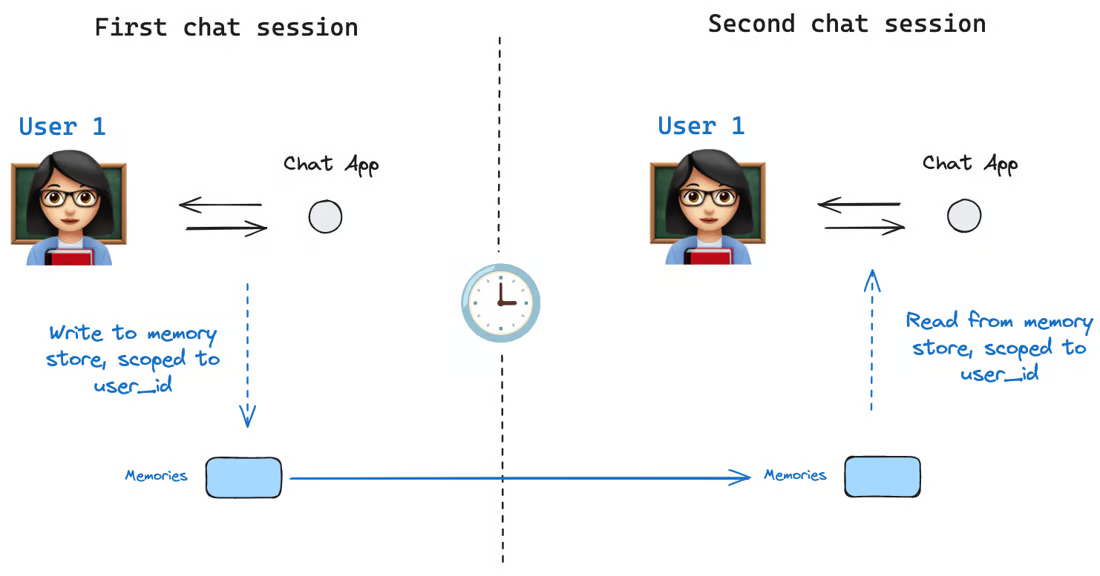

# 세팅

In [1]:
from dotenv import load_dotenv

load_dotenv()

True

# Listing items in a namespace

https://docs.langchain.com/oss/python/langgraph/stores#listing-items-in-a-namespace


`call` store.search또는 `async` store.asearch를 `no` query와 `no` 없이 호출하면 

`namespace` filter아래에 저장된 항목들이 namespace_prefix최대 `limit..`까지 반환됩니다  

의미론적 순위가 필요하지 않은 경우 네임스페이스 내의 모든 항목을 열거하는 데 사용하세요.


스토어 생성 및 데이터 준비

In [10]:
import uuid
from langgraph.store.memory import InMemoryStore

# 목록 조회 예제이므로 임베딩 없이 기본 스토어 생성
store = InMemoryStore()

# ("alice", "memories") 네임스페이스에 메모리 여러 개 저장
namespace = ("alice", "memories")

store.put(namespace, str(uuid.uuid4()), {"내용": "피자를 좋아합니다"})
store.put(namespace, str(uuid.uuid4()), {"내용": "아침에 커피를 마셔요"})
store.put(namespace, str(uuid.uuid4()), {"내용": "주말마다 등산을 갑니다"})

# 다른 하위 네임스페이스에도 저장 (프리픽스 매칭 확인용)
store.put(("alice", "preferences"), str(uuid.uuid4()), {"내용": "다크 모드 선호"})

# 다른 사용자 네임스페이스에도 저장 (조회에서 제외되는지 확인용)
store.put(("bob", "memories"), str(uuid.uuid4()), {"내용": "축구를 좋아합니다"})

 네임스페이스 전체 항목 조회 (query 없이 search)

In [11]:
# ("alice", "memories") 아래 저장된 항목을 최대 100개까지 반환
# query와 filter 없이 호출하면 시맨틱 검색이 아닌 단순 목록 조회
items = store.search(("alice", "memories"), limit=100)

# InMemoryStore는 삽입 순서대로 반환 (가장 최근 항목이 마지막)
for item in items:
    print(f"키: {item.key} | 값: {item.value}")

키: 0fba8902-570f-4c07-ac10-4cd08943f4ba | 값: {'내용': '피자를 좋아합니다'}
키: b0a78d0c-dbef-4731-a330-7011c4f8dea3 | 값: {'내용': '아침에 커피를 마셔요'}
키: 9053952d-6011-4c4f-8049-b11cc1b96e7f | 값: {'내용': '주말마다 등산을 갑니다'}


프리픽스 매칭 확인

In [12]:
# ("alice",) 프리픽스로 조회하면 하위 네임스페이스까지 모두 포함됨
# ("alice", "memories")와 ("alice", "preferences") 항목이 함께 반환
items = store.search(("alice",), limit=100)

for item in items:
    print(f"네임스페이스: {item.namespace} | 값: {item.value}")

네임스페이스: ('alice', 'memories') | 값: {'내용': '피자를 좋아합니다'}
네임스페이스: ('alice', 'memories') | 값: {'내용': '아침에 커피를 마셔요'}
네임스페이스: ('alice', 'memories') | 값: {'내용': '주말마다 등산을 갑니다'}
네임스페이스: ('alice', 'preferences') | 값: {'내용': '다크 모드 선호'}


페이지네이션 (offset으로 나눠서 조회)

In [13]:
# 항목이 많을 때 page_size 단위로 나눠서 순회
page_size = 2   # 예제 확인을 위해 작게 설정
offset = 0
page_num = 1

while True:
    page = store.search(("alice", "memories"), limit=page_size, offset=offset)
    if not page:
        break
    print(f"--- {page_num}페이지 ---")
    for item in page:
        print(f"값: {item.value}")
    offset += page_size
    page_num += 1

--- 1페이지 ---
값: {'내용': '피자를 좋아합니다'}
값: {'내용': '아침에 커피를 마셔요'}
--- 2페이지 ---
값: {'내용': '주말마다 등산을 갑니다'}


존재하는 네임스페이스 목록 조회 (list_namespaces)

In [14]:
# ("alice",)로 시작하는 모든 네임스페이스를 2단계 깊이까지 조회
namespaces = store.list_namespaces(prefix=("alice",), max_depth=2)
print(namespaces)

# 프리픽스 없이 호출하면 스토어의 모든 네임스페이스 조회
all_namespaces = store.list_namespaces()
print(all_namespaces)

[('alice', 'memories'), ('alice', 'preferences')]
[('alice', 'memories'), ('alice', 'preferences'), ('bob', 'memories')]


# Semantic search

https://docs.langchain.com/oss/python/langgraph/stores#semantic-search


단순 검색을 넘어, 이 저장소는 의미 검색도 지원하여 정확한 일치 항목이 아닌 의미를 기반으로 메모리를 찾을 수 있습니다. 

이를 활성화하려면 임베딩 모델을 사용하여 저장소를 구성하십시오.

시맨틱 검색이 활성화된 스토어 생성

In [6]:
import uuid
from langgraph.store.memory import InMemoryStore
from langchain.embeddings import init_embeddings

# 임베딩 모델을 인덱스로 지정하여 시맨틱 검색이 가능한 스토어 생성
store = InMemoryStore(
    index={
        "embed": init_embeddings("openai:text-embedding-3-small"),  # 임베딩 제공자
        "dims": 1536,                              # 임베딩 차원 수
        "fields": ["음식취향", "$"]                 # 임베딩할 필드 ("$"는 전체 값)
    }
)

# 네임스페이스: (user_id, "memories") 형태의 튜플로 메모리를 구분
user_id = "1"
namespace_for_memory = (user_id, "memories")

메모리 저장 (put)

In [7]:
# 특정 필드만 임베딩하여 저장
store.put(
    namespace_for_memory,
    str(uuid.uuid4()),
    {
        "음식취향": "저는 이탈리아 요리를 정말 좋아해요",
        "맥락": "저녁 식사 계획에 대해 대화 중"
    },
    index=["음식취향"]  # "음식취향" 필드만 임베딩
)

# 추가 메모리 저장 (스토어 기본 index 설정 사용)
store.put(
    namespace_for_memory,
    str(uuid.uuid4()),
    {"음식취향": "피자를 좋아합니다"}
)

store.put(
    namespace_for_memory,
    str(uuid.uuid4()),
    {"음식취향": "김치찌개 같은 매운 한식을 즐겨 먹어요"}
)

# 임베딩 없이 저장 (get으로 조회는 가능하지만 시맨틱 검색에는 걸리지 않음)
store.put(
    namespace_for_memory,
    str(uuid.uuid4()),
    {"시스템정보": "마지막 업데이트: 2024-01-01"},
    index=False
)

자연어 쿼리로 시맨틱 검색 (search)

In [8]:
# 음식 취향에 관한 메모리를 자연어 질의로 검색
memories = store.search(
    namespace_for_memory,
    query="사용자는 어떤 음식을 좋아하나요?",
    limit=3  # 상위 3개 결과 반환
)

# 검색 결과 출력 (score는 쿼리와의 유사도 점수)
for m in memories:
    print(f"유사도: {m.score:.4f} | 내용: {m.value}")

유사도: 0.5529 | 내용: {'음식취향': '피자를 좋아합니다'}
유사도: 0.4220 | 내용: {'음식취향': '김치찌개 같은 매운 한식을 즐겨 먹어요'}
유사도: 0.3691 | 내용: {'음식취향': '저는 이탈리아 요리를 정말 좋아해요', '맥락': '저녁 식사 계획에 대해 대화 중'}


다른 의미의 쿼리로 비교 검색

In [9]:
# 이탈리아 음식에 더 가까운 의미의 쿼리로 검색
memories = store.search(
    namespace_for_memory,
    query="파스타 같은 유럽 음식",
    limit=3
)

for m in memories:
    print(f"유사도: {m.score:.4f} | 내용: {m.value}")

유사도: 0.3740 | 내용: {'음식취향': '김치찌개 같은 매운 한식을 즐겨 먹어요'}
유사도: 0.3539 | 내용: {'음식취향': '피자를 좋아합니다'}
유사도: 0.3114 | 내용: {'음식취향': '저는 이탈리아 요리를 정말 좋아해요', '맥락': '저녁 식사 계획에 대해 대화 중'}


# Using in LangGraph

https://docs.langchain.com/oss/python/langgraph/stores#using-in-langgraph


스토어는 체크포인터와 긴밀하게 연동됩니다. 

체크포인터는 위에서 설명한 것처럼 스레드에 상태를 저장하고, 

스토어는 스레드 간에 접근할 수 있도록 임의의 정보를 저장할 수 있게 해줍니다 . 

체크포인터와 스토어를 모두 포함하여 그래프를 다음과 같이 컴파일하십시오.

스토어와 Context, 체크포인터 준비

In [15]:
import uuid
from dataclasses import dataclass
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import InMemorySaver

# 스레드 간 공유되는 장기 메모리 스토어
store = InMemoryStore()

# 그래프 호출 시 user_id를 전달하기 위한 컨텍스트 스키마
@dataclass
class Context:
    user_id: str

# 스레드(대화) 단위 상태 저장을 위한 체크포인터
checkpointer = InMemorySaver()

 노드 정의 (스토어에 저장하고 네임스페이스 항목 조회)

In [16]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.runtime import Runtime

# 노드 1: 사용자 메시지를 스토어에 메모리로 저장
def update_memory(state: MessagesState, runtime: Runtime[Context]):
    # 런타임 컨텍스트에서 user_id 가져오기
    user_id = runtime.context.user_id

    # (user_id, "memories") 튜플로 네임스페이스 지정
    namespace = (user_id, "memories")

    # 마지막 사용자 메시지를 새 메모리로 저장
    memory_id = str(uuid.uuid4())
    runtime.store.put(namespace, memory_id, {"내용": state["messages"][-1].content})

    return {}

# 노드 2: 네임스페이스의 전체 항목을 조회해서 응답 생성
def list_memories(state: MessagesState, runtime: Runtime[Context]):
    user_id = runtime.context.user_id
    namespace = (user_id, "memories")

    # query 없이 search 호출 → 네임스페이스 항목 목록 조회 (최대 100개)
    items = runtime.store.search(namespace, limit=100)

    # 조회된 메모리를 텍스트로 정리
    memory_list = "\n".join(f"- {item.value['내용']}" for item in items)
    reply = f"지금까지 저장된 메모리 {len(items)}개:\n{memory_list}"

    return {"messages": [{"role": "assistant", "content": reply}]}

그래프 정의 및 컴파일

In [17]:
# 컨텍스트 스키마를 지정하여 그래프 빌더 생성
builder = StateGraph(MessagesState, context_schema=Context)

# 노드와 엣지 추가
builder.add_node("update_memory", update_memory)
builder.add_node("list_memories", list_memories)
builder.add_edge(START, "update_memory")
builder.add_edge("update_memory", "list_memories")
builder.add_edge("list_memories", END)

# 체크포인터와 스토어를 함께 지정하여 컴파일
graph = builder.compile(checkpointer=checkpointer, store=store)

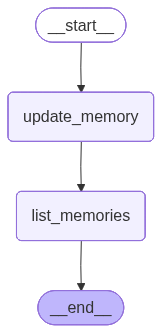

In [18]:
graph

스레드 1에서 그래프 실행

In [19]:
# 스레드 1로 그래프 호출
config = {"configurable": {"thread_id": "1"}}

for update in graph.stream(
    {"messages": [{"role": "user", "content": "안녕, 나는 피자를 좋아해"}]},
    config,
    stream_mode="updates",
    context=Context(user_id="1"),
):
    print(update)

{'update_memory': None}
{'list_memories': {'messages': [{'role': 'assistant', 'content': '지금까지 저장된 메모리 1개:\n- 안녕, 나는 피자를 좋아해'}]}}


같은 스레드에서 메모리 추가

In [20]:
# 같은 스레드에서 두 번째 메시지 전송
for update in graph.stream(
    {"messages": [{"role": "user", "content": "주말마다 등산을 다녀"}]},
    config,
    stream_mode="updates",
    context=Context(user_id="1"),
):
    print(update)

{'update_memory': None}
{'list_memories': {'messages': [{'role': 'assistant', 'content': '지금까지 저장된 메모리 2개:\n- 안녕, 나는 피자를 좋아해\n- 주말마다 등산을 다녀'}]}}


새 스레드에서도 같은 메모리 접근 확인

In [21]:
# 스레드 2 (새 대화)로 호출 — user_id가 같으면 기존 메모리에 접근 가능
config = {"configurable": {"thread_id": "2"}}

for update in graph.stream(
    {"messages": [{"role": "user", "content": "내 메모리를 알려줘"}]},
    config,
    stream_mode="updates",
    context=Context(user_id="1"),
):
    print(update)

{'update_memory': None}
{'list_memories': {'messages': [{'role': 'assistant', 'content': '지금까지 저장된 메모리 3개:\n- 안녕, 나는 피자를 좋아해\n- 주말마다 등산을 다녀\n- 내 메모리를 알려줘'}]}}


그래프 밖에서 직접 네임스페이스 조회

In [22]:
# 그래프 밖에서도 store 객체로 직접 항목 조회 가능
items = store.search(("1", "memories"), limit=100)
for item in items:
    print(f"키: {item.key} | 값: {item.value}")

# 존재하는 네임스페이스 목록 조회
print(store.list_namespaces(prefix=("1",), max_depth=2))

키: a930ad35-021f-449e-a692-8f880b84e59f | 값: {'내용': '안녕, 나는 피자를 좋아해'}
키: 4841394e-82e7-4dbc-b059-58fbf48690e2 | 값: {'내용': '주말마다 등산을 다녀'}
키: 275d27c9-16d5-46d8-a13c-ca81d9a07e9e | 값: {'내용': '내 메모리를 알려줘'}
[('1', 'memories')]
